# 피부 타입별 추천 상품의 리뷰 비율 시각화

피부 타입별 추천 상품을 세로로 나열하고, 각 상품의 **전체 리뷰에서 피부 타입별 비율**을 누적 막대로 표시합니다. 상품명 앞 번호는 표시하지 않습니다.

먼저 `code/04_추천시스템/recommend_products.ipynb`에서 추천 결과 CSV를 생성한 뒤, 이 노트북을 위에서 아래로 실행하세요. 이 노트북은 추천 모델을 다시 학습하지 않습니다.

## 1. 라이브러리와 경로 설정

Jupyter 커널은 프로젝트의 `.venv` 환경을 선택하세요. 프로젝트 내부 어디에서 실행해도 상위 폴더에서 루트를 찾습니다.

In [1]:
from pathlib import Path
import sys
import textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display, Image

PROJECT_ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
                     if (p / "code/common/project_utils.py").is_file()), None)
if PROJECT_ROOT is None:
    raise RuntimeError("프로젝트 폴더 내부에서 실행하세요.")
common_dir = str(PROJECT_ROOT / "code/common")
if common_dir not in sys.path:
    sys.path.insert(0, common_dir)
from skin_type_recommendations import SKIN_TYPES

DATA_PATH = PROJECT_ROOT / "outputs/data/recommendation/merged_output.csv"
RECOMMENDATIONS_PATH = PROJECT_ROOT / "outputs/data/recommendation/recommendations.csv"
SKIN_RECOMMENDATIONS_PATH = RECOMMENDATIONS_PATH.with_name("recommendations_by_skin_type.csv")
SUMMARY_PATH = PROJECT_ROOT / "outputs/reports/recommendation/skin_type_summary.csv"
OUT_DIR = PROJECT_ROOT / "outputs/figures/recommendation"
OUT_DIR.mkdir(parents=True, exist_ok=True)
print("프로젝트:", PROJECT_ROOT)


프로젝트: /Users/Shared/Cosmetic_recommendation-main


## 2. 피부 타입 순서와 한글 글꼴

색상과 범례는 모든 타입의 그래프에서 동일하게 사용합니다.

In [2]:
SKIN_MAP = {"건성": "Dry", "민감성": "Sensitive", "복합성": "Combination",
            "약건성": "Slightly Dry", "중성": "Normal", "지성": "Oily", "트러블성": "Troubled"}
SKIN_ORDER = ["Unknown", "Dry", "Sensitive", "Combination", "Slightly Dry", "Normal", "Oily", "Troubled"]
COLORS = ["#1B3A5C", "#2E5C8A", "#4A7EBB", "#A8C5E2", "#F5E6D3", "#F4A582", "#D66B2B", "#8B2E2E"]

def configure_font():
    installed = {f.name for f in font_manager.fontManager.ttflist}
    for name in ["AppleGothic", "Malgun Gothic", "NanumGothic", "DejaVu Sans"]:
        if name in installed:
            plt.rcParams["font.family"] = name
            break
    plt.rcParams["axes.unicode_minus"] = False

configure_font()
print("글꼴:", plt.rcParams["font.family"])

글꼴: ['AppleGothic']


## 3. 실제 리뷰와 타입별 추천 목록 불러오기

`skin_type`은 **추천 대상 집단**이고, 색상별 비율은 그 상품에 달린 **전체 리뷰의 피부 타입 구성비**입니다. 두 의미를 구분해 읽으세요.

In [3]:
for path in [DATA_PATH, SKIN_RECOMMENDATIONS_PATH, SUMMARY_PATH]:
    if not path.exists():
        raise FileNotFoundError(f"추천 노트북을 먼저 실행하세요: {path}")
reviews = pd.read_csv(DATA_PATH)
skin_recommendations = pd.read_csv(SKIN_RECOMMENDATIONS_PATH)
skin_summary = pd.read_csv(SUMMARY_PATH)
display(skin_summary)
display(skin_recommendations[["skin_type", "rank", "item_id", "final_score"]].head(10))

,skin_type,user_count,candidate_count,recommended_count,content_user_count
0,건성,1033,19,10,987
1,지성,1027,20,10,955
2,복합성,1536,19,10,1478
3,민감성,441,9,9,418
4,약건성,40,0,0,0
5,중성,43,0,0,0
6,트러블성,219,2,2,208


,skin_type,rank,item_id,final_score
0,건성,1,이즈앤트리 어니언 뉴페어 겔크림 80ml 대용량 기획 (+겔크림20ml+패드2매),0.878624
1,건성,2,[대용량기획] 한율 쑥시카 수분크림 110ml (+25ml+ 패드2매+흡착팩폼2ml),0.866812
2,건성,3,[9월 올영픽]이즈앤트리 어니언 뉴페어 겔크림 50ml 더블기획 (+20ml),0.837929
3,건성,4,라로슈포제 시카플라스트 멀티 리페어 크림 100ml (+15ml+시카밤3ml+시카선...,0.830967
4,건성,5,마몽드 블루 캐모마일 크림 60ml 기획 (+30ml),0.814583
5,건성,6,[응급진정/38% 여드름 개선] 로벡틴 시카케어 블레미쉬 클리어링 크림 50ml 리...,0.796858
6,건성,7,[쿨링진정] 아비브 어성초 크림 카밍 튜브 75ml,0.795189
7,건성,8,[강희재픽/추가증정한정기획] 아벤느 시칼파트 플러스 S.O.S 크림 100ml 2입...,0.784621
8,건성,9,[손상/장벽 리페어] 아벤느 시칼파트 플러스 SOS 리페어 크림 100ml 2입 기획,0.779006
9,건성,10,키엘 울트라 훼이셜 오일-프리 젤 크림 50ml,0.768747


## 4. 상품별 피부 타입 리뷰 비율 계산

전체 리뷰 수를 분모로 사용하고, 피부 정보가 없는 리뷰는 `Unknown`에 포함합니다. 각 상품의 비율 합은 1입니다. 추천 후보 필터는 알려진 피부 정보만 분모로 사용하므로 그 필터 비율과는 다릅니다.

In [4]:
def ratio_matrix(reviews, items):
    """Figure 3은 전체 리뷰를 분모로 사용해 Unknown 비율도 명시합니다.

    추천 필터는 알려진 정보만 사용하므로 필터의 분모와 다릅니다.
    """
    frame = reviews.rename(columns={"product_name": "item_id"}).copy()
    frame["skin_en"] = frame.skin_type.map(SKIN_MAP).fillna("Unknown")
    rows = []
    for item in items:
        sub = frame.loc[frame.item_id == item, "skin_en"]
        if sub.empty:
            raise ValueError(f"추천 제품의 원본 리뷰가 없습니다: {item}")
        rows.append(sub.value_counts(normalize=True).reindex(SKIN_ORDER, fill_value=0).to_numpy())
    return np.array(rows)

In [5]:
for skin, group in skin_recommendations.groupby("skin_type"):
    items = group.sort_values("rank").item_id.tolist()
    ratios = ratio_matrix(reviews, items)
    if not np.allclose(ratios.sum(axis=1), 1):
        raise ValueError(f"리뷰 비율의 합이 1이 아닙니다: {skin}")
print("모든 추천 상품의 비율 합계 확인 완료")

모든 추천 상품의 비율 합계 확인 완료


## 5. 누적 막대그래프 생성 함수

상품명 줄바꿈, 한글 범례, 고정 색상, 300dpi 저장을 적용합니다. 상품 앞 번호는 제거했습니다. 기준을 충족하는 후보가 없는 타입은 빈 상태를 명시합니다.

In [6]:
def plot_skin_type_review_ratios(reviews, recommendations, out_dir=OUT_DIR):
    """각 피부 타입 추천 목록의 전체 리뷰 피부 분포를 원본 Figure 3 형식으로 표시."""
    configure_font()
    out_dir = Path(out_dir) / "by_skin_type_review_ratio"
    out_dir.mkdir(parents=True, exist_ok=True)
    palette = ["#3B4CC0", "#6685ED", "#98B9FA", "#C9D7EF",
               "#EED1C3", "#F7A889", "#E7654F", "#B40426"]
    display_names = ["Unknown"] + [next(k for k, v in SKIN_MAP.items() if v == s)
                                  for s in SKIN_ORDER[1:]]
    for skin in SKIN_TYPES:
        selection = recommendations.loc[recommendations.skin_type == skin].sort_values("rank")
        items = selection.item_id.tolist()
        fig, ax = plt.subplots(figsize=(16, max(4, len(items)*.82)), layout="constrained")
        ax.set_title(f"Review ratio by skin type for the top {len(items)} products\n"
                     f"Recommended for {skin} ({SKIN_MAP[skin]})", fontsize=14, pad=14)
        if not items:
            ax.text(.5, .5, "No products meet the skin-type threshold", ha="center", va="center",
                    transform=ax.transAxes)
            ax.set_axis_off()
        else:
            data = ratio_matrix(reviews, items)
            y = np.arange(len(items))
            left = np.zeros(len(items))
            for j, (name, color) in enumerate(zip(display_names, palette)):
                ax.barh(y, data[:, j], left=left, color=color, label=name, height=.6)
                left += data[:, j]
            labels = [textwrap.fill(item, width=46, break_long_words=False,
                                    break_on_hyphens=False)
                      for item in items]
            ax.set(yticks=y, yticklabels=labels, xlim=(0, 1), xlabel="Review ratio", ylabel="Product name")
            ax.tick_params(axis="y", labelsize=10, length=0, pad=10)
            ax.set_xticks(np.linspace(0, 1, 6))
            ax.invert_yaxis()
            ax.grid(axis="x", linestyle="--", color="#AAAAAA", linewidth=.6, alpha=.6)
            ax.legend(title="Skin type", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=10)
        filename = f"figure3_review_ratio_{SKIN_MAP[skin].lower().replace(' ', '_')}.png"
        fig.savefig(out_dir / filename, dpi=300, facecolor="white")
        plt.close(fig)

## 6. 피부 타입별 이미지 저장

In [7]:
plot_skin_type_review_ratios(reviews, skin_recommendations, OUT_DIR)
ratio_dir = OUT_DIR / "by_skin_type_review_ratio"
for path in sorted(ratio_dir.glob("figure3_review_ratio_*.png")):
    print(path)

/Users/Shared/Cosmetic_recommendation-main/outputs/figures/recommendation/by_skin_type_review_ratio/figure3_review_ratio_combination.png
/Users/Shared/Cosmetic_recommendation-main/outputs/figures/recommendation/by_skin_type_review_ratio/figure3_review_ratio_dry.png
/Users/Shared/Cosmetic_recommendation-main/outputs/figures/recommendation/by_skin_type_review_ratio/figure3_review_ratio_normal.png
/Users/Shared/Cosmetic_recommendation-main/outputs/figures/recommendation/by_skin_type_review_ratio/figure3_review_ratio_oily.png
/Users/Shared/Cosmetic_recommendation-main/outputs/figures/recommendation/by_skin_type_review_ratio/figure3_review_ratio_sensitive.png
/Users/Shared/Cosmetic_recommendation-main/outputs/figures/recommendation/by_skin_type_review_ratio/figure3_review_ratio_slightly_dry.png
/Users/Shared/Cosmetic_recommendation-main/outputs/figures/recommendation/by_skin_type_review_ratio/figure3_review_ratio_troubled.png


## 7. 원하는 피부 타입 이미지 확인

`PREVIEW_SKIN`을 건성, 지성, 복합성, 민감성, 약건성, 중성, 트러블성 중 하나로 바꾸면 됩니다.

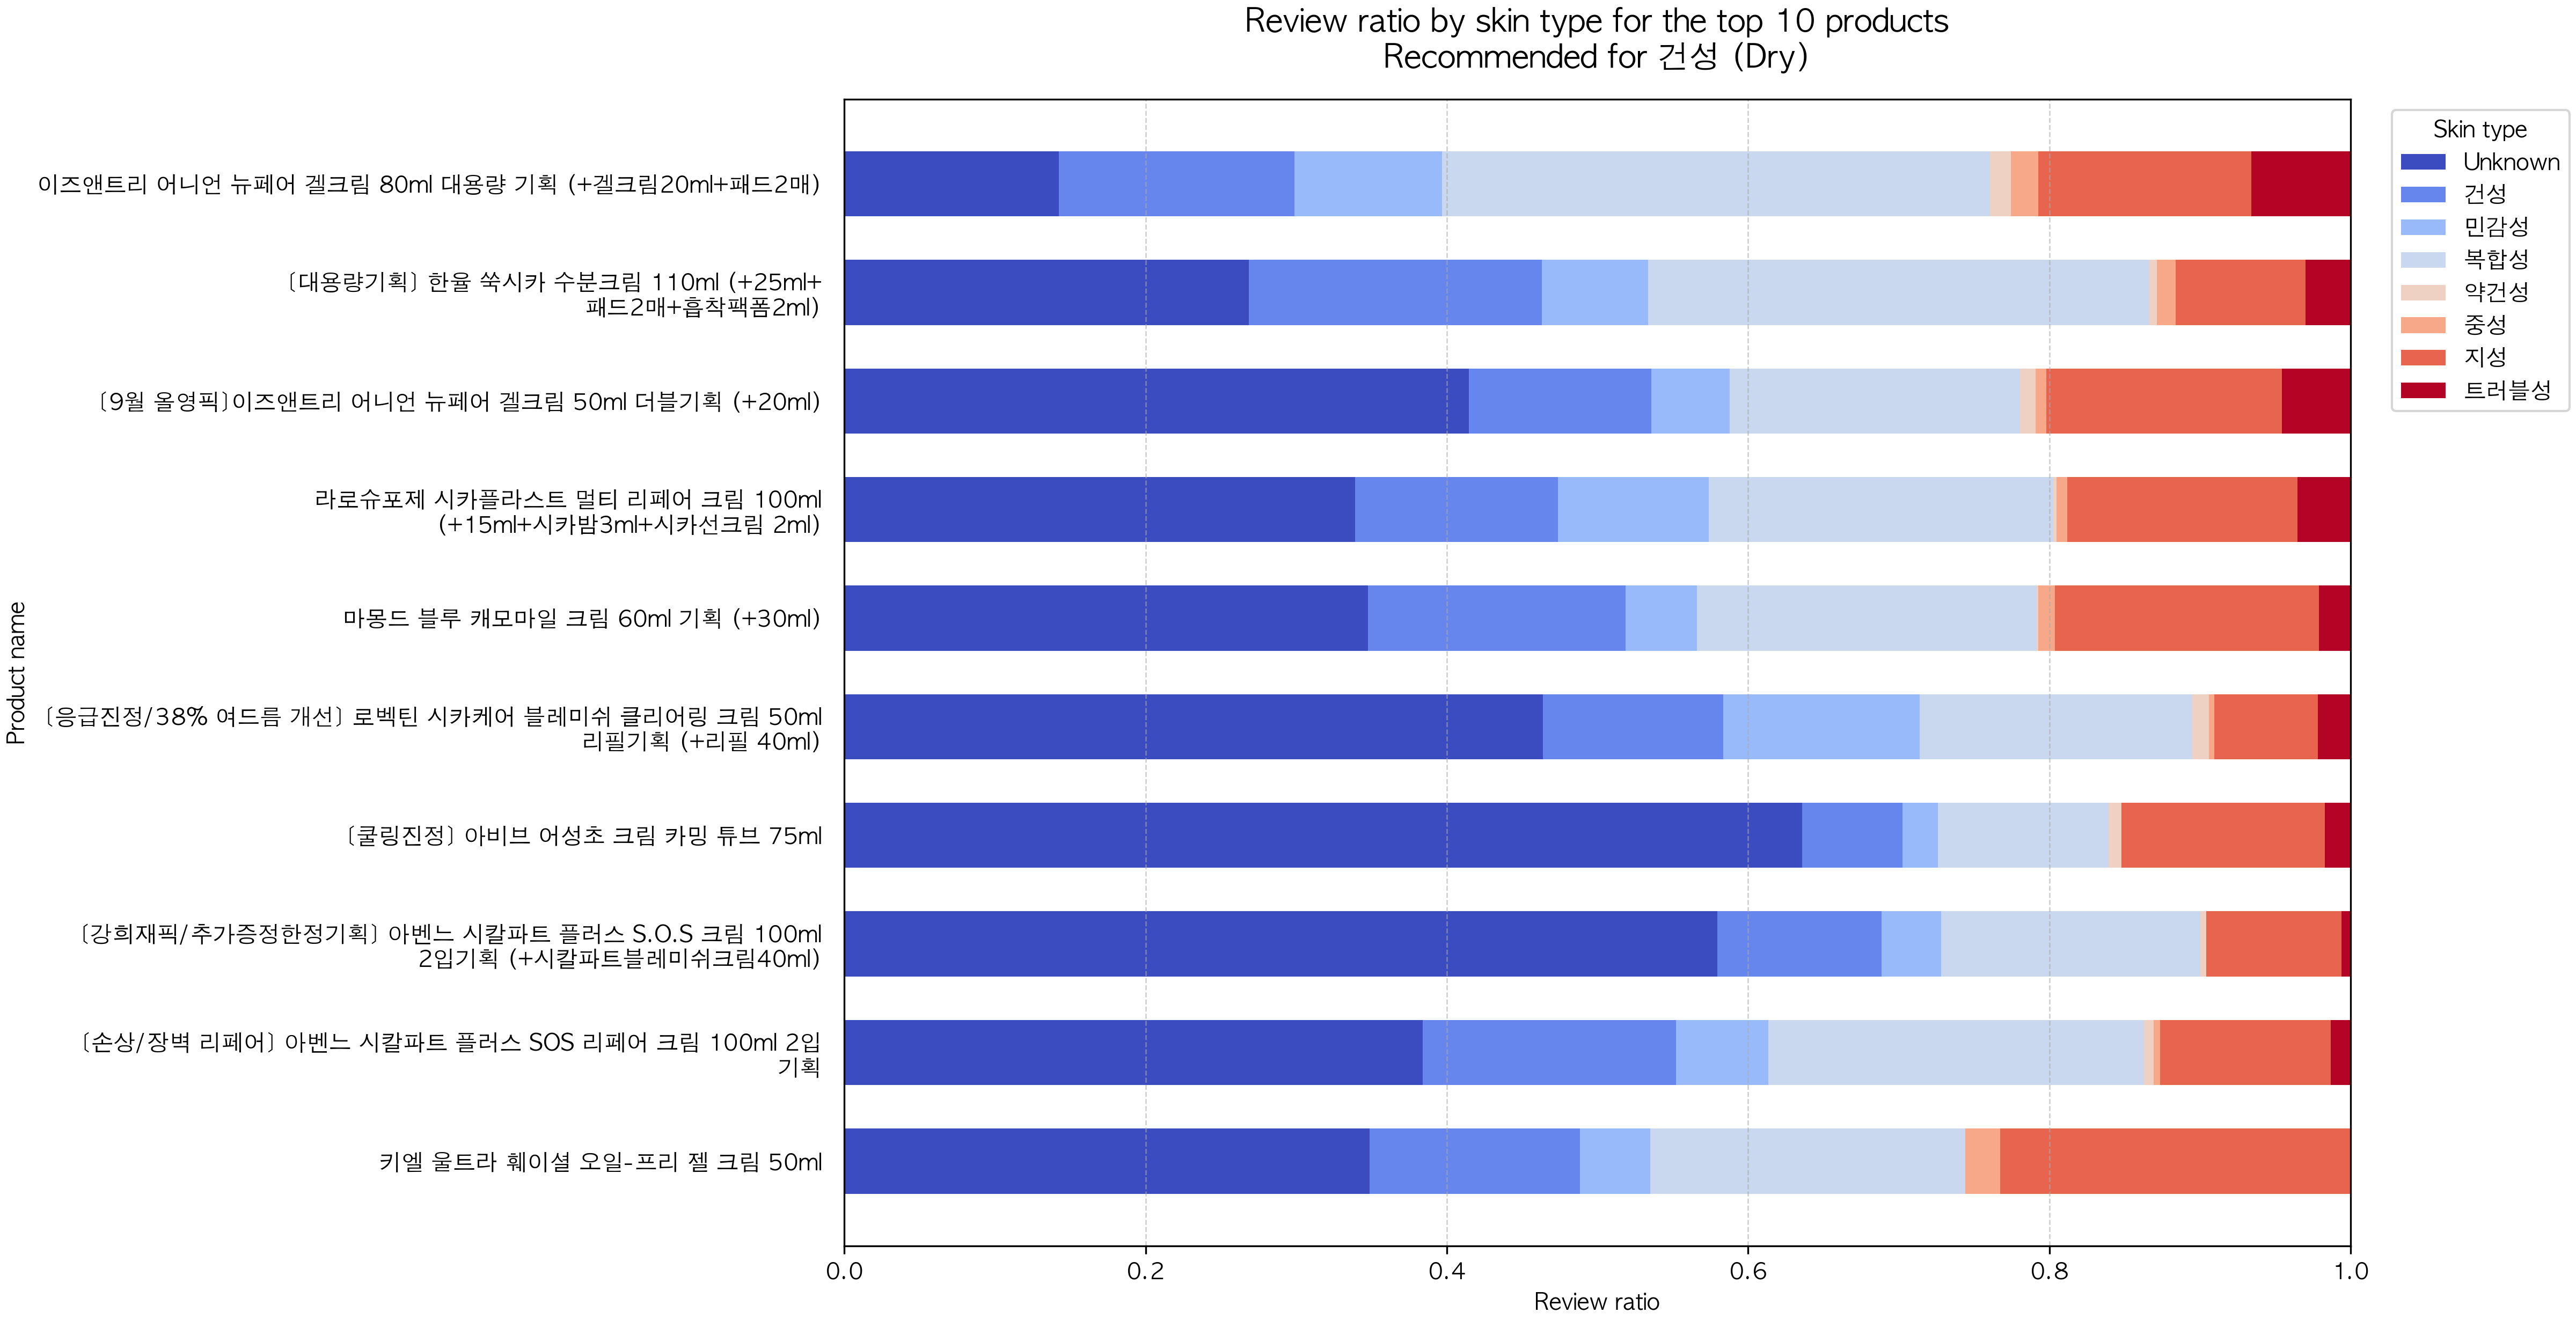

In [8]:
PREVIEW_SKIN = "건성"
if PREVIEW_SKIN not in SKIN_MAP:
    raise ValueError(f"피부 타입을 확인하세요: {PREVIEW_SKIN}")
preview_path = ratio_dir / f"figure3_review_ratio_{SKIN_MAP[PREVIEW_SKIN].lower().replace(' ', '_')}.png"
display(Image(filename=str(preview_path), width=1200))

## 8. 선택 사항 타입별 추천 점수 그래프

누적 리뷰 비율 대신 최종 추천 점수를 보고 싶으면 `GENERATE_SCORE_FIGURES`를 `True`로 바꾸세요. 타입별 후보 안에서 정규화한 점수이므로 타입 간 점수 크기를 직접 비교하지 않습니다.

In [9]:
def plot_skin_type_recommendations(recommendations, summary, out_dir=OUT_DIR):
    """타입별 Top K를 통합 그림과 개별 300dpi 그림으로 저장합니다."""
    configure_font()
    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    details = out_dir / "by_skin_type"
    details.mkdir(exist_ok=True)

    def draw(ax, skin, size=9):
        data = recommendations.loc[recommendations.skin_type == skin].sort_values("rank")
        info = summary.loc[summary.skin_type == skin].iloc[0]
        ax.set_title(f"{skin} ({SKIN_MAP[skin]}) — Top {len(data)}\n"
                     f"Users: {info.user_count:,} | Candidates: {info.candidate_count}", fontsize=size+2, pad=12)
        if data.empty:
            ax.text(.5, .5, "No products meet the skin-type threshold", ha="center", va="center",
                    transform=ax.transAxes, fontsize=size)
            ax.set_axis_off()
            return
        labels = [textwrap.fill(f"{rank}. {item}", width=38, break_long_words=False,
                                break_on_hyphens=False)
                  for rank, item in zip(data["rank"], data.item_id)]
        y = np.arange(len(data))
        ax.barh(y, data.final_score, height=.56, color=COLORS[SKIN_ORDER.index(SKIN_MAP[skin])])
        ax.set(yticks=y, yticklabels=labels, xlim=(0, 1.17), xlabel="Hybrid score (within skin type)")
        ax.tick_params(axis="y", labelsize=size, length=0, pad=8)
        ax.invert_yaxis()
        ax.set_axisbelow(True)
        ax.grid(axis="x", color="#D9D9D9", linestyle="--", linewidth=.5)
        ax.spines[["top", "right", "left"]].set_visible(False)
        for pos, score in enumerate(data.final_score):
            ax.text(score+.015, pos, f"{score:.4f}", va="center", fontsize=size)

    fig, axes = plt.subplots(4, 2, figsize=(28, 30), layout="constrained")
    for ax, skin in zip(axes.flat, SKIN_TYPES):
        draw(ax, skin)
    axes.flat[-1].axis("off")
    axes.flat[-1].text(0, .7, "Recommendations are computed separately for each skin type.\n"
                      "Candidates must meet the skin-type review ratio threshold.\n"
                      "Scores are normalized within each type, not across types.\n"
                      "Fewer than 10 results means fewer eligible products.",
                      fontsize=14, linespacing=1.8, transform=axes.flat[-1].transAxes)
    fig.savefig(out_dir / "figure3_skin_type_top10_recommendations.png", dpi=200, facecolor="white")
    plt.close(fig)
    for skin in SKIN_TYPES:
        fig, ax = plt.subplots(figsize=(16, 9), layout="constrained")
        draw(ax, skin, size=11)
        fig.savefig(details / f"top10_{SKIN_MAP[skin].lower().replace(' ', '_')}.png",
                    dpi=300, facecolor="white")
        plt.close(fig)

In [10]:
GENERATE_SCORE_FIGURES = False
if GENERATE_SCORE_FIGURES:
    plot_skin_type_recommendations(skin_recommendations, skin_summary, OUT_DIR)

## 9. 선택 사항 개인 추천 Figure 3과 Figure 4

특정 사용자 한 명의 추천 결과가 필요하면 `GENERATE_PERSONAL_FIGURES`를 `True`로 바꾸세요. 피부 타입별 집단 추천과 별개의 결과입니다.

In [11]:
def plot_recommendation_figures(reviews, recommendations, out_dir=OUT_DIR):
    configure_font()
    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    if recommendations.empty:
        # 이전 실행 그림이 새 결과처럼 남지 않도록 빈 상태를 명시합니다.
        for filename in ["figure3_skin_ratio_top10_products.png", "figure4_hybrid_top10_scores.png"]:
            fig, ax = plt.subplots(figsize=(8, 3))
            ax.text(.5, .5, "No unseen candidate products", ha="center", va="center")
            ax.axis("off")
            fig.savefig(out_dir / filename, dpi=180)
            plt.close(fig)
        return
    items = recommendations.item_id.tolist()
    data = ratio_matrix(reviews, items)
    y = np.arange(len(items))
    fig, ax = plt.subplots(figsize=(15, max(5, len(items)*.55)))
    left = np.zeros(len(items))
    for j, (skin, color) in enumerate(zip(SKIN_ORDER, COLORS)):
        ax.barh(y, data[:, j], left=left, label=skin, color=color)
        left += data[:, j]
    ax.set(yticks=y, yticklabels=items, xlim=(0, 1), xlabel="Review ratio",
           title=f"Skin type distribution of {len(items)} recommended products")
    ax.invert_yaxis()
    ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
    fig.tight_layout()
    fig.savefig(out_dir / "figure3_skin_ratio_top10_products.png", dpi=180, bbox_inches="tight")
    plt.close(fig)

    # 긴 상품명은 생략하지 않고 줄바꿈하여 논문 삽입 시에도 읽을 수 있게 합니다.
    labels = [textwrap.fill(f"{rank}. {item}", width=48,
                            break_long_words=False, break_on_hyphens=False)
              for rank, item in enumerate(items, start=1)]
    fig, ax = plt.subplots(figsize=(16, max(6, len(items)*.85)))
    ax.barh(y, recommendations.final_score, height=.58, color="#2E5C8A")
    ax.set(yticks=y, yticklabels=labels, xlim=(0, 1.08), xlabel="Hybrid score (relative to candidates)",
           title=f"Hybrid recommendation scores for the top {len(items)} products")
    ax.tick_params(axis="y", labelsize=11, length=0, pad=12)
    ax.tick_params(axis="x", labelsize=11)
    ax.set_axisbelow(True)
    ax.grid(axis="x", color="#D9D9D9", linewidth=.6, linestyle="--")
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.invert_yaxis()
    for position, score in enumerate(recommendations.final_score):
        ax.text(score+.012, position, f"{score:.6f}", va="center", fontsize=11)
    fig.tight_layout()
    fig.savefig(out_dir / "figure4_hybrid_top10_scores.png", dpi=300, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    print("실제 추천 결과 그림 저장:", out_dir)

In [12]:
GENERATE_PERSONAL_FIGURES = False
if GENERATE_PERSONAL_FIGURES:
    personal_recommendations = pd.read_csv(RECOMMENDATIONS_PATH)
    plot_recommendation_figures(reviews, personal_recommendations, OUT_DIR)